# Chemical dispersion in an industrial mixing device

This notebook addresses Problem 2 of Assignment 1 through a POD–Galerkin model for stationary advection–diffusion. It includes 50 training and 50 independent test simulations, Dirichlet lifting, POD compression, affine projection, test validation, and optimization at $x_0=(1.5,0.25)$.

## 0. Libraries and full-order model

Import the numerical, finite-element, sampling, and plotting libraries. The first cell checks FEM conversion before using the dataset.

In [1]:
import numpy as np
import dlroms.fespaces as fe
from scipy.stats import qmc
import matplotlib.pyplot as plt
from IPython.display import clear_output

%load_ext autoreload
%autoreload 2
import MixerFunctions as mixer
from fenics_numpy_compat import check
check(fe, mixer.Vh)
check(fe, mixer.Vb)
print("Verified FEM conversion; NumPy", np.__version__)

clear_output()

## 1. Problem formulation

We consider the stationary dispersion of a chemical inside a two-dimensional mixing chamber containing three rotating cylinders. The goal is to construct a **POD-Galerkin Reduced Order Model (ROM)** capable of efficiently predicting the concentration field for different cylinder rotational velocities.

The concentration $u_\mu:\Omega\rightarrow\mathbb{R}$ satisfies the stationary advection-diffusion problem:

$$
\begin{cases}
-\varepsilon\Delta u_\mu+\mathbf{b}_\mu\cdot\nabla u_\mu=0 & \text{in }\Omega,\\
u_\mu=g(y)=\exp[-25(y-1)^2] & \text{on }\Gamma_{\mathrm{in}},\\
\nabla u_\mu\cdot\mathbf{n}=0 & \text{on }\partial\Omega\setminus\Gamma_{\mathrm{in}},
\end{cases}
$$

where $\varepsilon=0.005$ is the fixed diffusion coefficient, $\mathbf{b}_\mu$ is the fluid velocity field and $\Gamma_{\mathrm{in}}$ denotes the left inlet boundary.

The parameter vector $\mu=(c_1,c_2,c_3)\in[-5,5]^3$ describes the rotational velocities of the three cylinders. Since the underlying Stokes problem is linear, the velocity field admits an affine decomposition:

$$
\mathbf{b}_\mu=\mathbf{b}_0+\sum_{i=1}^{3}c_i\mathbf{b}_i,
$$

where $\mathbf{b}_0$ accounts for the fixed inlet flow and $\mathbf{b}_i$ represents the contribution of the $i$-th rotating cylinder.

The weak formulation is obtained by multiplying the governing equation by a test function $v$ vanishing on $\Gamma_{\mathrm{in}}$ and integrating by parts:

$$
\varepsilon\int_\Omega\nabla u_\mu\cdot\nabla v\,d\Omega
+\int_\Omega(\mathbf{b}_\mu\cdot\nabla u_\mu)v\,d\Omega=0.
$$

The Full Order Model (FOM) discretizes this problem using continuous piecewise-linear finite elements, resulting in $N_h=2763$ degrees of freedom.

The affine dependence of the velocity field will later enable the precomputation of parameter-independent reduced operators, making the online POD-Galerkin solution particularly efficient.

### Finite element discretization

Discretizing the weak formulation using the finite element basis functions $\{\phi_i\}_{i=1}^{N_h}$ leads to the algebraic system

$$
A_h(\mu)\,u_h(\mu)=f_h(\mu),
$$

where $u_h(\mu)\in\mathbb{R}^{N_h}$ contains the nodal degrees of freedom, $A_h(\mu)\in\mathbb{R}^{N_h\times N_h}$ is the full-order system matrix, and $f_h(\mu)$ represents the right-hand side after accounting for the prescribed boundary conditions.

The matrix entries are derived from the weak formulation:

$$
\big(A_h(\mu)\big)_{ij}
=
\int_\Omega
\left[
\varepsilon\nabla\phi_j\cdot\nabla\phi_i
+
(\mathbf b_\mu\cdot\nabla\phi_j)\phi_i
\right]\,d\Omega.
$$

Since the velocity field depends affinely on the cylinder rotational parameters, the discrete operator admits the decomposition

$$
A_h(\mu)=A_0+\sum_{k=1}^{3}c_kA_k,
$$

where $A_0$ accounts for diffusion and the fixed background flow, while $A_k$ represents the advective contribution associated with the $k$-th cylinder.

This affine structure will later allow the reduced operators to be precomputed offline, avoiding the assembly of full-order matrices for every new parameter configuration.

## 2. Full-order dataset

### 2.1 Parameter sampling

Generate 50 training samples using **Latin Hypercube Sampling (LHS)** and 50 independent test samples drawn uniformly from the parameter domain $[-5,5]^3$, as required by the assignment.

LHS divides the range of each parameter into 50 equally sized intervals, draws one random value from each interval, and independently permutes the values across the three parameter coordinates to construct 50 parameter vectors. This ensures that every interval is represented exactly once along each coordinate, providing better marginal coverage than standard random sampling, although uniform coverage of the full three-dimensional space is not guaranteed.

This strategy is particularly useful with a limited training budget, as it promotes parameter diversity when constructing the POD basis. The independently sampled test set is reserved for assessing ROM accuracy on unseen configurations. Fixed random seeds ensure reproducibility.

In [2]:
Ntrain = 50
Ntest = 50
nparams = 3

# Latin Hypercube Sampling for training
sampler = qmc.LatinHypercube(d=nparams, seed=42)
mu_train_unit = sampler.random(n=Ntrain)

# Map [0,1]^3 -> [-5,5]^3
mu_train = qmc.scale(
    mu_train_unit,
    l_bounds=[-5, -5, -5],
    u_bounds=[ 5,  5,  5]
)

# Uniform sampling for testing data
rng = np.random.default_rng(123)

mu_test = rng.uniform(
    low=-5,
    high=5,
    size=(Ntest, nparams)
)

print(f"Training set has dimesnion {mu_train.shape}")
print(f"Test set has dimesnion {mu_test.shape}")


Training set has dimesnion (50, 3)
Test set has dimesnion (50, 3)


### 2.2 Snapshot generation

For each sampled parameter vector $\mu^{(j)}$, the FOM solves the stationary advection-diffusion problem and returns a finite-element concentration vector $u_h(\mu^{(j)})\in\mathbb{R}^{N_h}$.

The resulting training snapshot matrix is assembled column-wise:

$$
U_{\mathrm{train}}=
\begin{bmatrix}
u_h(\mu^{(1)}) & u_h(\mu^{(2)}) & \cdots & u_h(\mu^{(50)})
\end{bmatrix}
\in\mathbb{R}^{N_h\times50},
\qquad N_h=2763.
$$

An analogous matrix $U_{\mathrm{test}}\in\mathbb{R}^{N_h\times50}$ is generated from independently sampled parameters. Only the training snapshots will be used for POD basis construction; the test solutions will serve as reference fields for evaluating the ROM.

The FOM execution time is recorded for each simulation to establish a computational baseline for the subsequent speedup analysis. The generated datasets and timings are stored in FOMdata_assignment1.npz, allowing them to be reloaded without repeating the full-order simulations.

In [3]:
from pathlib import Path
from time import perf_counter

dataset_path = Path("FOMdata_assignment1.npz")

if dataset_path.exists():

    # Load previously generated dataset
    with np.load(dataset_path) as data:
        mu_train = data["mu_train"]
        U_train = data["U_train"]
        mu_test = data["mu_test"]
        U_test = data["U_test"]
        times_train = data["times_train"]
        times_test = data["times_test"]

    print("FOM dataset loaded from cache.")

else:

    print("Dataset not found. Generating FOM snapshots...")

    Nh = mixer.Vh.dim()

    U_train = np.zeros((Nh, len(mu_train)))
    U_test = np.zeros((Nh, len(mu_test)))

    times_train = np.zeros(len(mu_train))
    times_test = np.zeros(len(mu_test))

    # Training snapshots
    for i, mu in enumerate(mu_train):
        tic = perf_counter()

        U_train[:, i] = mixer.FOMsolver(mu)

        times_train[i] = perf_counter() - tic
        print(f"Training FOM {i+1:02d}/{len(mu_train)} - {times_train[i]:.3f} s")

    # Test snapshots
    for i, mu in enumerate(mu_test):
        tic = perf_counter()

        U_test[:, i] = mixer.FOMsolver(mu)

        times_test[i] = perf_counter() - tic
        print(f"Test FOM {i+1:02d}/{len(mu_test)} - {times_test[i]:.3f} s")

    # Save dataset and timings
    np.savez_compressed(
        dataset_path,
        mu_train=mu_train,
        U_train=U_train,
        mu_test=mu_test,
        U_test=U_test,
        times_train=times_train,
        times_test=times_test
    )

    print(f"\nFOM dataset saved to {dataset_path}")

# Dataset summary
Nh = U_train.shape[0]
Ntrain = U_train.shape[1]
Ntest = U_test.shape[1]

assert U_train.shape == (mixer.Vh.dim(), len(mu_train))
assert U_test.shape == (mixer.Vh.dim(), len(mu_test))

print("\n--- FOM Dataset Summary ---")
print(f"FOM dimension:       {Nh}")
print(f"Training snapshots:  {Ntrain}")
print(f"Test snapshots:      {Ntest}")
print(f"Average FOM time:    {times_test.mean():.4f} s")
print(f"Total FOM time:      {times_train.sum() + times_test.sum():.2f} s")

FOM dataset loaded from cache.

--- FOM Dataset Summary ---
FOM dimension:       2763
Training snapshots:  50
Test snapshots:      50
Average FOM time:    0.0925 s
Total FOM time:      8.88 s


In [4]:
print(f"Train snapshots matrix has dimension {U_train.shape}")
print(f"Test snapshots matrix has dimension {U_test.shape}")

Train snapshots matrix has dimension (2763, 50)
Test snapshots matrix has dimension (2763, 50)


### 2.3 FOM visualization

Visualize a representative training solution to inspect the spatial concentration distribution and verify the consistency of the computed field with the prescribed inlet boundary condition.

Parameter: [-0.155  2.312 -2.372]
Concentration range: [1.389e-11, 1.000e+00]


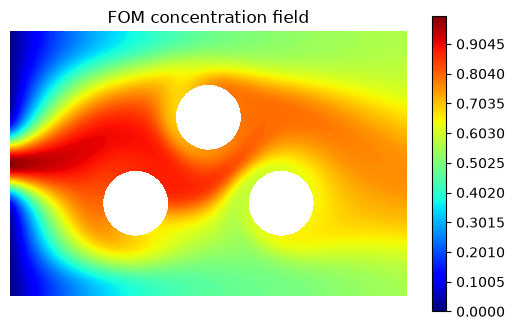

In [5]:
u_check = U_train[:, 0]  # First snapshot as example

print(f"Parameter: {np.round(mu_train[0], 3)}")
print(f"Concentration range: [{u_check.min():.3e}, {u_check.max():.3e}]")

fe.plot(u_check, mixer.Vh, colorbar=True)
plt.title("FOM concentration field")
plt.show()

## 3. Lifting the nonhomogeneous Dirichlet condition

### 3.1 Reference solution

The prescribed inlet concentration $u_\mu=g\neq 0$ introduces a nonhomogeneous Dirichlet boundary condition. Directly constructing a linear POD space from the original snapshots would not guarantee that arbitrary reduced approximations preserve this boundary condition.

To overcome this issue, we introduce a parameter-independent **lifting function** $u_s$ satisfying the prescribed inlet data and decompose the solution as

$$
u_\mu=u_s+w_\mu,
\qquad
w_\mu|_{\Gamma_{\mathrm{in}}}=0.
$$

We choose the FOM solution corresponding to zero cylinder rotations as the lifting function:

$$
u_s=u_h(\mu_s),\qquad \mu_s=(0,0,0).
$$

This choice satisfies the required inlet condition while retaining the fixed inlet-driven flow. Since the Dirichlet data are independent of $\mu$, the same lifting can be used for every parameter configuration.

The reduced model can therefore approximate the homogeneous correction $w_\mu$ in a linear reduced space, while the original concentration field is recovered by adding $u_s$.

In [6]:
mu_special = np.array([0.0, 0.0, 0.0]) 
u_special = mixer.FOMsolver(mu_special)  # Selected lifting solution

### 3.2 Lifted snapshot matrix

The FOM simulations generated in Section 2 provide a collection of concentration fields, each corresponding to a different parameter configuration. Since the finite element solution is represented by $N_h$ nodal degrees of freedom, each snapshot can be expressed as a vector $u_h(\mu^{(j)})\in\mathbb{R}^{N_h}$.

Collecting the $N_{\mathrm{train}}$ training solutions as columns gives the **snapshot matrix**

$$
U_{\mathrm{train}}=
\begin{bmatrix}
| & | & & |\\
u_h(\mu^{(1)}) & u_h(\mu^{(2)}) & \cdots & u_h(\mu^{(N_{\mathrm{train}})})\\
| & | & & |
\end{bmatrix}
\in\mathbb{R}^{N_h\times N_{\mathrm{train}}}.
$$

Before applying POD, the lifting function $u_s$ is subtracted from each snapshot to obtain the homogeneous correction fields

$$
w_h(\mu^{(j)})=u_h(\mu^{(j)})-u_s.
$$

The resulting **lifted snapshot matrix** is therefore

$$
W_{\mathrm{train}}
=
\begin{bmatrix}
w_h(\mu^{(1)}) & \cdots & w_h(\mu^{(N_{\mathrm{train}})})
\end{bmatrix}
=
U_{\mathrm{train}}-u_s\mathbf{1}^{T}
\in\mathbb{R}^{N_h\times N_{\mathrm{train}}},
$$

where $\mathbf{1}\in\mathbb{R}^{N_{\mathrm{train}}}$ is a vector of ones, so that $u_s$ is subtracted from every column.

Since all lifted snapshots satisfy homogeneous Dirichlet conditions on $\Gamma_{\mathrm{in}}$, any linear combination of them also satisfies these conditions. Consequently, the POD basis constructed from $W_{\mathrm{train}}$ will span an admissible homogeneous reduced space.


$$
w_\mu|_{\Gamma_{\mathrm{in}}}
=u_\mu|_{\Gamma_{\mathrm{in}}}-u_s|_{\Gamma_{\mathrm{in}}}
=g-g=0.
$$

The original concentration field can then be recovered by adding back the lifting function:

$$
u_h(\mu)=u_s+w_h(\mu).
$$

In the next section, the lifted snapshot matrix will be decomposed using Singular Value Decomposition (SVD) to identify the dominant spatial modes and construct a low-dimensional approximation space.

In [7]:
W_train = U_train - u_special[:, None]

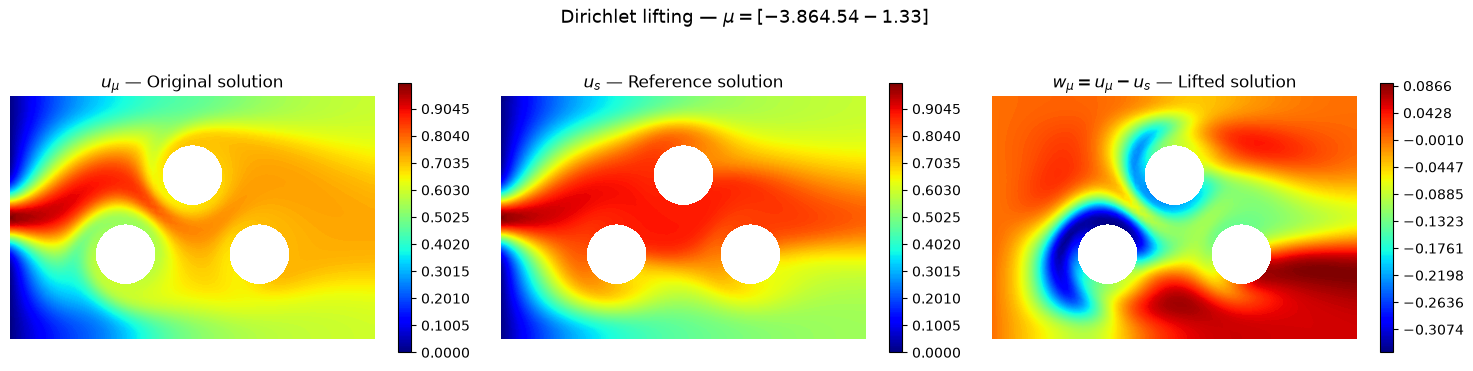

In [8]:
i = 25  # Random snapshot to plot

mu = mu_train[i]
u_mu = U_train[:, i]
w_mu = W_train[:, i]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

fields = [u_mu, u_special, w_mu]
titles = [
    r"$u_\mu$ — Original solution",
    r"$u_s$ — Reference solution",
    r"$w_\mu = u_\mu - u_s$ — Lifted solution"
]

for ax, field, title in zip(axes, fields, titles):
    plt.sca(ax)
    fe.plot(field, mixer.Vh, colorbar=True,
            vmin=field.min(), vmax=field.max())
    ax.set_title(title)

fig.suptitle(rf"Dirichlet lifting — $\mu = {np.round(mu, 2)}$", fontsize=13)
plt.tight_layout()
plt.show()

## 4. POD basis and dimension study

### 4.1 Singular value decomposition

Starting from the lifted training snapshot matrix $W_{\mathrm{train}}\in\mathbb{R}^{N_h\times N_{\mathrm{train}}}$, we compute its **thin (economy) Singular Value Decomposition (SVD)**:

$$
W_{\mathrm{train}}=U\Sigma Z^T,
$$

where, defining $r=\min(N_h,N_{\mathrm{train}})$,

$$
U\in\mathbb{R}^{N_h\times r},\qquad
\Sigma\in\mathbb{R}^{r\times r},\qquad
Z\in\mathbb{R}^{N_{\mathrm{train}}\times r}.
$$

The columns of $U$ are orthonormal spatial modes, $\Sigma=\operatorname{diag}(\sigma_1,\ldots,\sigma_r)$ contains the singular values in descending order, and the columns of $Z$ describe the corresponding coefficients across the training snapshots.

In this problem, $N_h=2763$ and $N_{\mathrm{train}}=50$, hence $r=50$ and

$$
U\in\mathbb{R}^{2763\times50},\qquad
\Sigma\in\mathbb{R}^{50\times50},\qquad
Z\in\mathbb{R}^{50\times50}.
$$

Using the thin SVD avoids computing the complete $2763\times2763$ matrix of left singular vectors, reducing memory requirements and computational cost. Moreover, the snapshot matrix has rank at most 50, so no additional left singular vectors are needed to represent its column space.

The **Proper Orthogonal Decomposition (POD)** constructs the reduced basis by retaining the first $N$ left singular vectors:

$$
V_N=
\begin{bmatrix}
u_1 & u_2 & \cdots & u_N
\end{bmatrix}
=U[:,\, :N]
\in\mathbb{R}^{N_h\times N},
\qquad N\ll N_h.
$$

By the Eckart–Young theorem, this truncated basis minimizes the aggregate squared Euclidean reconstruction error over the training snapshots:

$$
\left\|W_{\mathrm{train}}-V_NV_N^TW_{\mathrm{train}}\right\|_F^2
=\sum_{i>N}\sigma_i^2.
$$

Thus, the decay of the singular values determines how efficiently the training snapshot matrix can be approximated in a low-dimensional linear space.

Here, POD is performed using the Euclidean inner product of the FEM coefficient vectors, rather than the mass-weighted spatial $L^2(\Omega)$ inner product.

In [9]:
U_pod, singular_values, VT = np.linalg.svd(
    W_train,
    full_matrices=False
)

print("W_train:", W_train.shape)
print("U_pod:", U_pod.shape)
print("singular_values:", singular_values.shape)
print("VT:", VT.shape)

W_train: (2763, 50)
U_pod: (2763, 50)
singular_values: (50,)
VT: (50, 50)


### 4.2 Singular-value decay and retained energy

The decay of the singular values provides an indication of the intrinsic reducibility of the lifted solution manifold. A rapid decay implies that a small number of dominant POD modes can represent most of the training snapshot content.

To quantify the effect of truncation, we define the cumulative retained energy:

$$
E_N=\frac{\sum_{i=1}^{N}\sigma_i^2}{\sum_{i=1}^{N_{\mathrm{train}}}\sigma_i^2}.
$$

Here, energy refers to the squared Euclidean magnitude of the snapshots, not to a physical energy quantity. The corresponding aggregate relative reconstruction error is

$$
\frac{\|W_{\mathrm{train}}-V_NV_N^TW_{\mathrm{train}}\|_F}
{\|W_{\mathrm{train}}\|_F}
=\sqrt{1-E_N}.
$$

We examine the singular-value decay and the number of modes required to reach different energy thresholds as preliminary indicators for choosing the reduced dimension. The final choice must also account for the projection accuracy and the subsequent Galerkin ROM performance.

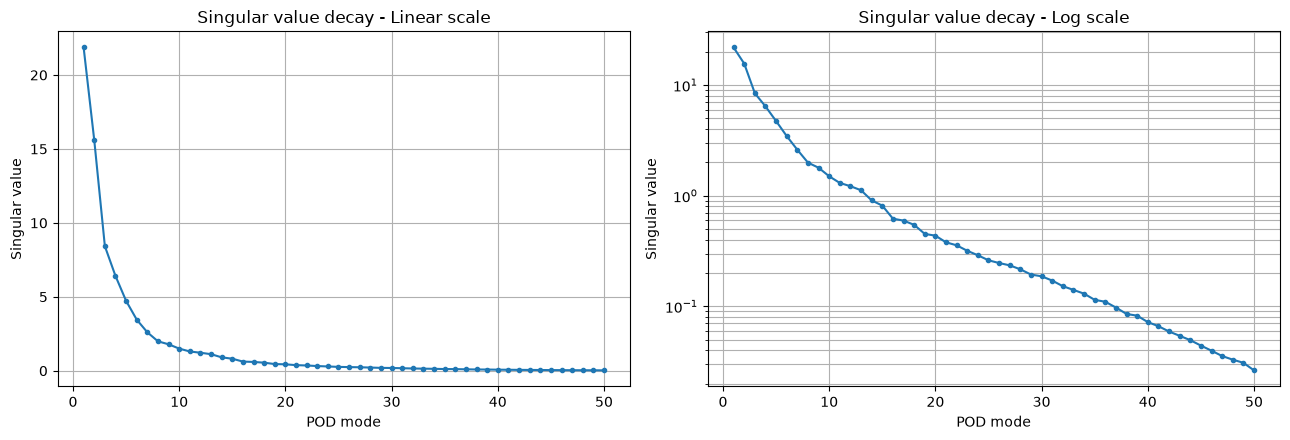

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

modes = np.arange(1, len(singular_values) + 1)

# Linear scale
ax[0].plot(
    modes,
    singular_values,
    "o-",
    markersize=3
)

ax[0].set_xlabel("POD mode")
ax[0].set_ylabel("Singular value")
ax[0].set_title("Singular value decay - Linear scale")
ax[0].grid(True)


# Logarithmic scale
ax[1].semilogy(
    modes,
    singular_values,
    "o-",
    markersize=3
)

ax[1].set_xlabel("POD mode")
ax[1].set_ylabel("Singular value")
ax[1].set_title("Singular value decay - Log scale")
ax[1].grid(True, which="both")

plt.tight_layout()
plt.show()

In [11]:
energy = np.cumsum(singular_values**2) / np.sum(singular_values**2)

thresholds = [0.95, 0.99, 0.999, 0.9999, 0.99999]

for threshold in thresholds:
    n_required = np.searchsorted(energy, threshold) + 1
    print(f"{100*threshold:.3f}% energy -> N = {n_required}")

95.000% energy -> N = 5
99.000% energy -> N = 10
99.900% energy -> N = 21
99.990% energy -> N = 34
99.999% energy -> N = 44


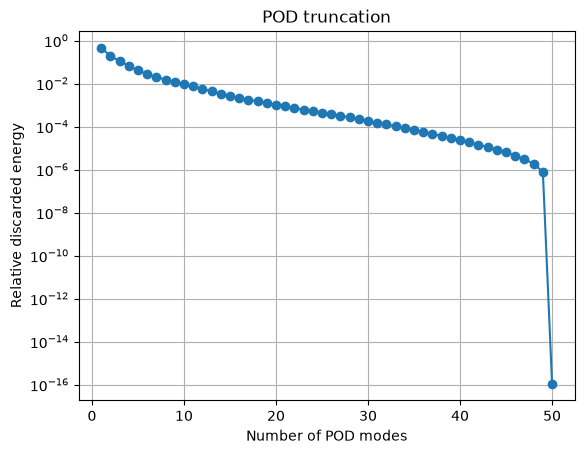

In [12]:
lost_energy = 1 - energy

plt.figure()

plt.semilogy(
    np.arange(1, len(lost_energy) + 1),
    lost_energy,
    "o-"
)

plt.xlabel("Number of POD modes")
plt.ylabel("Relative discarded energy")
plt.title("POD truncation")
plt.grid(True)
plt.show()

### 4.3 Training and test projection errors

The retained energy provides an aggregate measure of POD truncation, but does not directly quantify the relative approximation error for individual solutions.

We therefore evaluate the projection of each lifted snapshot onto the reduced space:

$$
w_N(\mu)=V_NV_N^Tw_h(\mu),
$$

and compute the relative projection error:

$$
e_{\mathrm{proj}}(\mu,N)=
\frac{\|w_h(\mu)-w_N(\mu)\|_2}
{\|w_h(\mu)\|_2}.
$$

The mean errors are evaluated over the training and independent test datasets for increasing values of $N$.

The training error measures how accurately the POD basis represents the snapshots from which it was constructed, while the test error assesses its representation of unseen parameter configurations.

These projection errors are normalized by the norm of the lifted field $w_h = u_h - u_s$. The Galerkin validation errors reported later are instead normalized by the norm of the complete concentration field $u_h$. Consequently, their percentage values are not directly comparable.

In [13]:
# Lifted test snapshots
W_test = U_test - u_special[:, None]

N_values = np.arange(1, U_pod.shape[1] + 1)

mean_proj_error_train = []
mean_proj_error_test = []

for N in N_values:

    V = U_pod[:, :N]

    # -------------------------
    # Training set
    # -------------------------
    errors_train = []

    for j in range(W_train.shape[1]):

        w = W_train[:, j]
        w_proj = V @ (V.T @ w)

        error = (
            np.linalg.norm(w - w_proj)
            / np.linalg.norm(w)
        )

        errors_train.append(error)

    mean_proj_error_train.append(
        100 * np.mean(errors_train)
    )

    # -------------------------
    # Test set
    # -------------------------
    errors_test = []

    for j in range(W_test.shape[1]):

        w = W_test[:, j]
        w_proj = V @ (V.T @ w)

        error = (
            np.linalg.norm(w - w_proj)
            / np.linalg.norm(w)
        )

        errors_test.append(error)

    mean_proj_error_test.append(
        100 * np.mean(errors_test)
    )

mean_proj_error_train = np.array(mean_proj_error_train)
mean_proj_error_test = np.array(mean_proj_error_test)

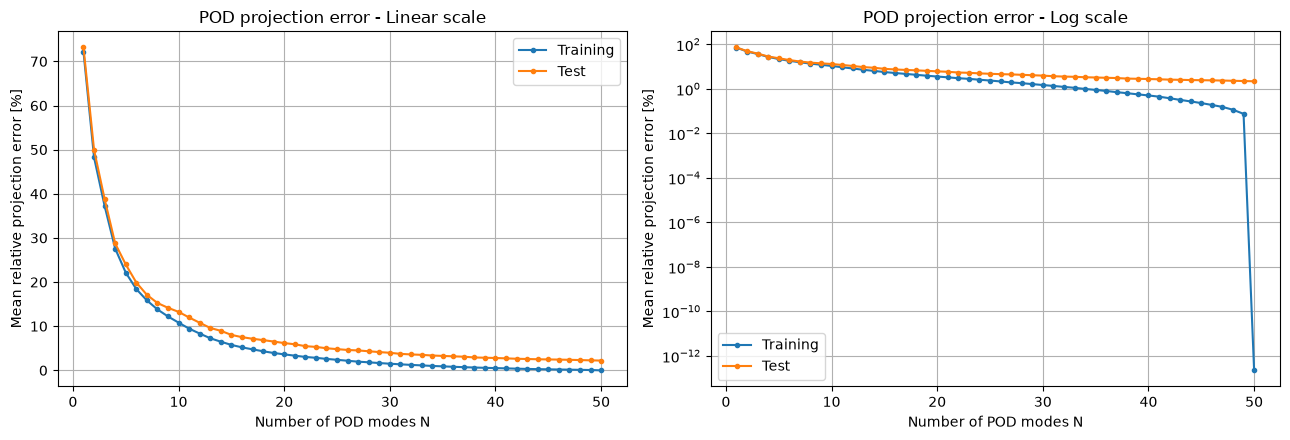

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# --------------------------------------------------
# Linear scale
# --------------------------------------------------

ax[0].plot(
    N_values,
    mean_proj_error_train,
    marker='o',
    markersize=3,
    label='Training'
)

ax[0].plot(
    N_values,
    mean_proj_error_test,
    marker='o',
    markersize=3,
    label='Test'
)

ax[0].set_xlabel('Number of POD modes N')
ax[0].set_ylabel('Mean relative projection error [%]')
ax[0].set_title('POD projection error - Linear scale')

ax[0].grid(True)
ax[0].legend()


# --------------------------------------------------
# Logarithmic scale
# --------------------------------------------------

ax[1].semilogy(
    N_values,
    mean_proj_error_train,
    marker='o',
    markersize=3,
    label='Training'
)

ax[1].semilogy(
    N_values,
    mean_proj_error_test,
    marker='o',
    markersize=3,
    label='Test'
)

ax[1].set_xlabel('Number of POD modes N')
ax[1].set_ylabel('Mean relative projection error [%]')
ax[1].set_title('POD projection error - Log scale')

ax[1].grid(True, which='both')
ax[1].legend()

plt.tight_layout()
plt.show()

The POD basis and its candidate dimensions are determined using training snapshots only. Projection errors are then evaluated on both training and independent test samples to assess how well the reduced space represents unseen configurations.

The test results are reported as a generalization assessment rather than used to construct or update the POD basis.

**Choice of projection norm.** The POD basis is constructed using the Euclidean inner product of the finite-element coefficient vectors, rather than the mass-weighted $L^2(\Omega)$ inner product.

To assess the impact of this choice, the same POD projections were evaluated using both the Euclidean and spatial $L^2$ relative errors, with

$$
\|w_h\|_{L^2(\Omega)}^2=\mathbf{w}^TM\mathbf{w},
$$

where $M$ is the finite-element mass matrix.

For $N=10,20,30,40$, the differences between the two error metrics remain below 0.2 percentage points. Thus, the error assessment is only weakly affected by the choice of norm for the configurations examined. We retain the Euclidean POD formulation to preserve the simpler implementation.

In [15]:
# Diagnostic only: Euclidean vs spatial L2 error

M = fe.assemble(
    lambda u, v: fe.inner(u, v) * fe.dx,
    mixer.Vh
)

def l2_norm(x):
    """Return the scalar FEM L2 norm sqrt(x.T @ M @ x) using the assembled mass matrix."""
    return np.sqrt(x @ (M @ x))

N_values = [10, 20, 30, 40]
all_differences = []

for n in N_values:
    V = U_pod[:, :n]

    err_euclidean = []
    err_l2 = []

    for j in range(W_test.shape[1]):
        w = W_test[:, j]
        w_proj = V @ (V.T @ w)
        residual = w - w_proj

        err_euclidean.append(
            np.linalg.norm(residual) / np.linalg.norm(w)
        )

        err_l2.append(
            l2_norm(residual) / l2_norm(w)
        )

    err_euclidean = np.array(err_euclidean)
    err_l2 = np.array(err_l2)

    # Difference in percentage points for this N
    differences = 100 * (err_euclidean - err_l2)
    all_differences.extend(differences)

    print(
        f"N={n:2d} | "
        f"Euclidean: {100*err_euclidean.mean():.3f}% | "
        f"L2: {100*err_l2.mean():.3f}% | "
        f"Difference: {differences.mean():+.3f} pp"
    )

all_differences = np.array(all_differences)

print(
    f"\nMean absolute difference across all N and test samples: "
    f"{np.abs(all_differences).mean():.3f} percentage points"
)

N=10 | Euclidean: 13.255% | L2: 13.061% | Difference: +0.194 pp
N=20 | Euclidean: 6.180% | L2: 6.022% | Difference: +0.158 pp
N=30 | Euclidean: 3.981% | L2: 3.839% | Difference: +0.141 pp
N=40 | Euclidean: 2.797% | L2: 2.679% | Difference: +0.118 pp

Mean absolute difference across all N and test samples: 0.155 percentage points


### 4.4 Spatial POD modes

The first three POD modes are visualized to inspect the dominant spatial patterns extracted from the lifted concentration snapshots.

Unlike the original concentration fields, POD modes represent spatial correction patterns and may take both positive and negative values. Their signs are arbitrary, and their relative importance is determined by the corresponding singular values.

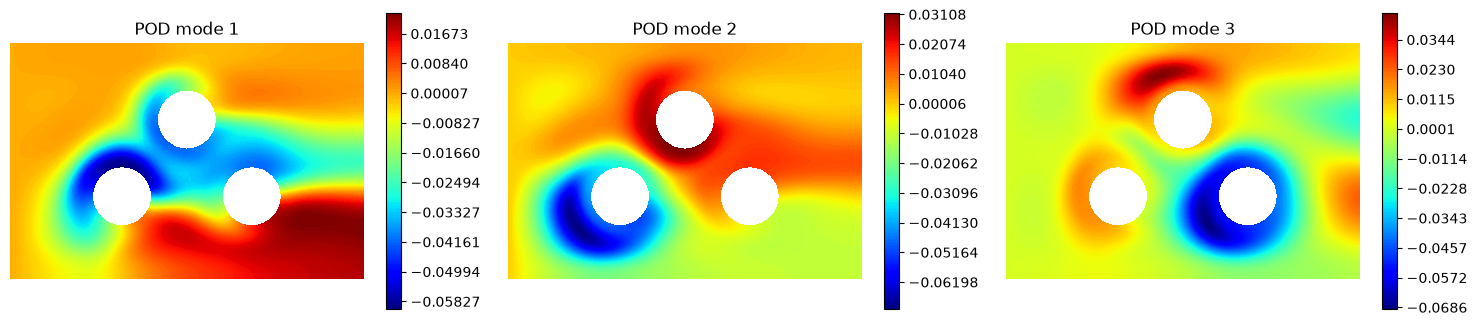

In [16]:
mixer.plot_pod_modes(U_pod, mixer.Vh, [1, 2, 3], ncols=3)

### 4.5 Preliminary POD dimension selection

The reduced dimension is initially selected based on the singular-value decay, requiring a cumulative retained energy of at least $99.99\%$ over the training snapshots:

$$
N_{\mathrm{POD}}=\min\left\{N:\frac{\sum_{i=1}^{N}\sigma_i^2}{\sum_{i=1}^{N_{\mathrm{train}}}\sigma_i^2}\geq 0.9999\right\}.
$$

This criterion yields **$N_{\mathrm{POD}}=34$**, corresponding to an aggregate relative training reconstruction error of approximately $1\%$ in the Euclidean norm.

The mean relative projection error over individual training snapshots is also evaluated to assess the practical accuracy of this choice.

This dimension provides an initial candidate for the POD-Galerkin ROM, whose actual accuracy may differ from that of the orthogonal POD projection. The final reduced dimension will therefore be reassessed by comparing Galerkin accuracy and computational cost.

In [17]:
N_candidate = 34

V = U_pod[:, :N_candidate]

W_proj = V @ (V.T @ W_train)

errors = np.linalg.norm(W_train - W_proj, axis=0) / np.linalg.norm(W_train, axis=0)

retained_energy = (
    np.sum(singular_values[:N_candidate]**2)
    / np.sum(singular_values**2)
)

print(f"Selected POD dimension: N = {N_candidate}")
print(f"Retained energy:         {100 * retained_energy:.5f}%")
print(f"Mean training error:     {100 * errors.mean():.3f}%")
print(f"Maximum training error:  {100 * errors.max():.3f}%")

Selected POD dimension: N = 34
Retained energy:         99.99163%
Mean training error:     1.002%
Maximum training error:  2.336%


## 5. Affine POD–Galerkin reduced model

### 5.1 Homogeneous reduced space

The POD basis $V_N\in\mathbb{R}^{N_h\times N}$ was constructed from the lifted snapshots, which satisfy homogeneous Dirichlet conditions at the inlet.

We approximate the homogeneous correction field as a linear combination of the retained POD modes:

$$
w_N(\mu)=V_Na_N(\mu)=\sum_{i=1}^{N}a_i(\mu)v_i,
$$

where $a_N(\mu)\in\mathbb{R}^{N}$ is the vector of **reduced coefficients**, representing the contribution of each POD mode to the solution at a given parameter configuration $\mu$.

Adding back the lifting function gives the reduced approximation of the original concentration field:

$$
u_N(\mu)=u_s+V_Na_N(\mu).
$$

Since all lifted snapshots vanish on the inlet boundary, their POD modes must also satisfy the homogeneous Dirichlet condition. We verify this property numerically at the constrained degrees of freedom:

$$
V_N|_{\Gamma_{\mathrm{in}}}=0.
$$

Consequently, any reduced approximation automatically preserves the prescribed inlet concentration, independently of the values of the reduced coefficients.

The coefficients $a_N(\mu)$ are not known a priori: in the following sections, they will be determined by projecting the governing equations onto the reduced space using the Galerkin method.

In [18]:
from fenics import DirichletBC, Constant

bc0 = DirichletBC(
    mixer.Vh,
    Constant(0.0),
    lambda x, on_boundary: on_boundary and mixer.left(x)
)

dirichlet_dofs = np.array(
    list(bc0.get_boundary_values().keys()), dtype=int
)

N_candidate = 34
V = U_pod[:, :N_candidate]

boundary_error = np.max(np.abs(V[dirichlet_dofs, :]))

print(f"Dirichlet DOFs: {len(dirichlet_dofs)}")
print(f"Maximum POD boundary violation: {boundary_error:.3e}")

Dirichlet DOFs: 41
Maximum POD boundary violation: 0.000e+00


### 5.2 Affine decomposition and offline projection

**Full-order finite element operator**

Starting from the weak formulation of the advection-diffusion equation, we introduce the parameter-dependent bilinear form

$$
a_\mu(u,v)
=
\int_\Omega
\left[
\varepsilon\nabla u\cdot\nabla v
+
(\mathbf b_\mu\cdot\nabla u)v
\right]\,d\Omega,
$$

where $u$ is the trial function, $v$ is the test function, and $\mathbf b_\mu$ is the parameter-dependent velocity field.

Let $\{\phi_j\}_{j=1}^{N_h}$ denote the finite element basis functions. For the continuous piecewise-linear finite elements employed here, each $\phi_j$ is associated with a mesh node, equals one at that node and zero at the other nodes, and is piecewise linear over the mesh elements.

A finite element field is represented as a linear combination of these basis functions:

$$
u_h(x;\mu)=\sum_{j=1}^{N_h}(u_h(\mu))_j\,\phi_j(x),
$$

where $u_h(\mu)\in\mathbb R^{N_h}$ is the vector of nodal coefficients.

The discrete operator $A_h(\mu)\in\mathbb R^{N_h\times N_h}$ is obtained by evaluating the bilinear form on pairs of basis functions:

$$
\bigl(A_h(\mu)\bigr)_{ij}=a_\mu(\phi_j,\phi_i).
$$

Thus, each matrix entry describes the contribution of the $j$-th trial basis function to the weak equation associated with the $i$-th test basis function.

Since the velocity field depends affinely on the rotational parameters,

$$
\mathbf b_\mu=\mathbf b_0+\sum_{k=1}^{3}c_k\mathbf b_k,
$$

the discrete operator admits the decomposition

$$
A_h(\mu)=A_0+\sum_{k=1}^{3}c_kA_k,
$$

where $A_0$ contains diffusion and fixed inlet advection, while $A_1,A_2,A_3$ represent the advective contributions of the rotating cylinders. All four operators belong to $\mathbb R^{N_h\times N_h}$.

**Galerkin projection onto the POD space**

Using the lifted reduced approximation introduced in Section 5.1,

$$
u_N(\mu)=u_s+V_Na_N(\mu),
$$

the Galerkin method imposes orthogonality of the discrete residual to the homogeneous reduced space:

$$
V_N^TA_h(\mu)\bigl(u_s+V_Na_N(\mu)\bigr)=0.
$$

Rearranging yields the reduced system

$$
\underbrace{V_N^TA_h(\mu)V_N}_{A_N(\mu)}
a_N(\mu)
=
\underbrace{-V_N^TA_h(\mu)u_s}_{f_N(\mu)},
$$

where

$$
A_N(\mu)\in\mathbb R^{N\times N},
\qquad
f_N(\mu),a_N(\mu)\in\mathbb R^N.
$$

**Offline precomputation**

Exploiting the affine decomposition, we precompute the parameter-independent reduced operators

$$
A_{k,N}=V_N^TA_kV_N\in\mathbb R^{N\times N},
$$

$$
f_{k,N}=-V_N^TA_ku_s\in\mathbb R^N,
\qquad k=0,1,2,3.
$$

These operations constitute the **offline phase**. The full-order matrices are assembled from the original weak formulation before algebraic modification for Dirichlet conditions. Since the POD basis functions vanish on the constrained boundary degrees of freedom, their Galerkin projection is consistent with the homogeneous correction problem.

As a consistency check, the reference solution $u_s$ solves the FOM at $\mu=(0,0,0)$. Its projected residual should therefore vanish:

$$
f_{0,N}=-V_N^TA_0u_s\approx0.
$$

A near-zero norm confirms consistency between the lifting function and the projected reference operator.

In [19]:
# Assemble parameter-independent FOM operators
A0, A1, A2, A3 = mixer.assemble_affine_operators()

# Offline Galerkin projection
A_full = [A0, A1, A2, A3]

A_red = [V.T @ A @ V for A in A_full]
f_red = [-V.T @ (A @ u_special) for A in A_full]

print(f"Full-order dimension: {A0.shape[0]}")
print(f"Reduced dimension:    {V.shape[1]}")
print(f"Reduced operators:    {len(A_red)} matrices of shape {A_red[0].shape}")
print(f"Reference projected residual ||f0,N||: {np.linalg.norm(f_red[0]):.3e}")

Full-order dimension: 2763
Reduced dimension:    34
Reduced operators:    4 matrices of shape (34, 34)
Reference projected residual ||f0,N||: 1.375e-17


### 5.3 Online assembly and queryable ROM

For any new parameter vector $\mu=(c_1,c_2,c_3)$, the reduced operators are assembled through affine combinations of the precomputed quantities:

$$
A_N(\mu)=A_{0,N}+\sum_{i=1}^{3}c_iA_{i,N},
$$

$$
f_N(\mu)=f_{0,N}+\sum_{i=1}^{3}c_if_{i,N}.
$$

The reduced coefficients are obtained by solving

$$
A_N(\mu)a_N(\mu)=f_N(\mu),
$$

and the full concentration field is reconstructed as

$$
u_N(\mu)=u_s+V_Na_N(\mu).
$$

The online system involves only $N$ unknowns, rather than $N_h=2763$. Assembly and solution of the reduced system are independent of the FOM dimension, while full-field reconstruction requires an additional operation involving $N_h$.

The function `build_ROM(N)` encapsulates the offline construction for a chosen reduced dimension and returns reusable functions for querying the ROM and its reduced coefficients. A pointwise concentration objective is also included for the subsequent optimization task.

In [20]:
from fenics import Point

x0 = Point(1.5, 0.25)

def build_ROM(N):

    """Build an N-mode affine POD-Galerkin model using the existing lifted basis.
    
    Project the full-order operators offline. Return three callables: a full-field
    solver, a reduced-coefficient solver, and concentration at the target point.
    Each callable accepts the three cylinder velocities mu."""
    V = U_pod[:, :N]

    # Offline reduced operators
    A_red = [V.T @ A @ V for A in A_full]
    f_red = [-V.T @ (A @ u_special) for A in A_full]

    def coefficients(mu):
        """Assemble and solve the reduced affine system for cylinder velocities mu."""
        c1, c2, c3 = mu

        AN = A_red[0] + c1*A_red[1] + c2*A_red[2] + c3*A_red[3]
        fN = f_red[0] + c1*f_red[1] + c2*f_red[2] + c3*f_red[3]

        return np.linalg.solve(AN, fN)

    def solver(mu):
        """Return the lifted full-field ROM concentration for cylinder velocities mu."""
        return u_special + V @ coefficients(mu)

    def objective(mu):
        """Return the ROM concentration at the target point for cylinder velocities mu."""
        u_rom = solver(mu)
        u_rom_fun = fe.asfunction(u_rom, mixer.Vh)
        return u_rom_fun(x0)

    return solver, coefficients, objective

In [21]:
RBsolver, RBcoefficients, objective = build_ROM(N_candidate) # Initialization with candidate N

### 5.4 First ROM verification

As an initial consistency check, we compare the POD-Galerkin solution with a reference FOM solution for an independent test parameter.

The relative error in the Euclidean norm is computed as

$$
e_{\mathrm{ROM}}(\mu)=
\frac{\|u_h(\mu)-u_N(\mu)\|_2}
{\|u_h(\mu)\|_2}.
$$

Unlike the POD projection error, this quantity evaluates the complete reduced solver, including the effects of Galerkin projection and the reduced linear system.

We visualize the FOM solution, the reconstructed ROM field, and their pointwise difference. A systematic assessment over the entire test set and different reduced dimensions follows in Section 6.

Parameter: [ 1.824 -4.462 -2.796]
Relative ROM error: 0.414%


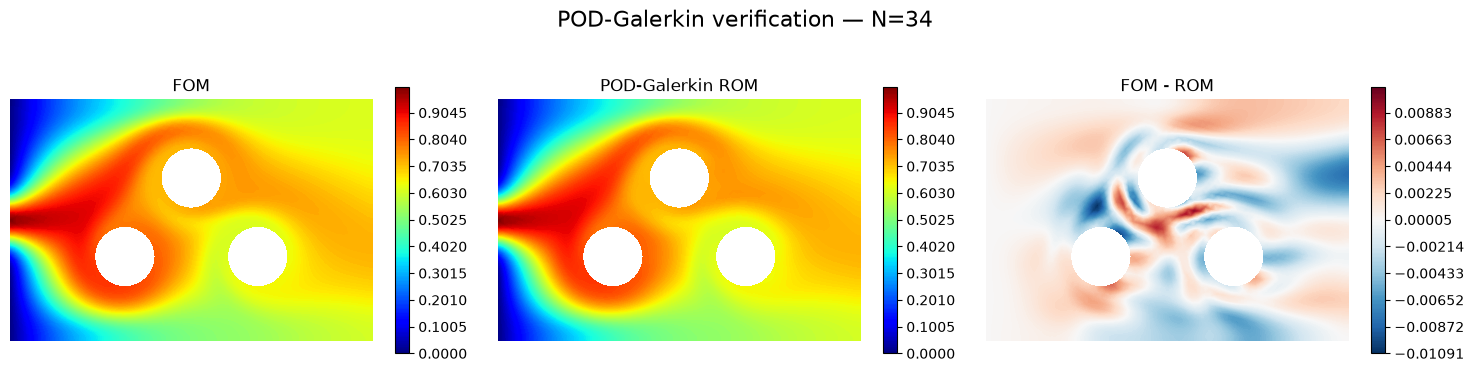

In [22]:
mu = mu_test[0]

u_fom = U_test[:, 0]
u_rom = RBsolver(mu)

rel_error = (
    np.linalg.norm(u_fom - u_rom)
    / np.linalg.norm(u_fom)
)

print(f"Parameter: {np.round(mu, 3)}")
print(f"Relative ROM error: {100*rel_error:.3f}%")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

fields = [u_fom, u_rom, u_fom - u_rom]
titles = ["FOM", "POD-Galerkin ROM", "FOM - ROM"]

vmin = min(u_fom.min(), u_rom.min())
vmax = max(u_fom.max(), u_rom.max())

for i, (ax, field, title) in enumerate(zip(axes, fields, titles)):
    plt.sca(ax)

    if i < 2:
        fe.plot(field, mixer.Vh, colorbar=True, vmin=vmin, vmax=vmax)
    else:
        bound = max(abs(field.min()), abs(field.max()))
        fe.plot(field, mixer.Vh, colorbar=True,
                vmin=-bound, vmax=bound, cmap="RdBu_r")

    ax.set_title(title)
fig.suptitle(
    f"POD-Galerkin verification — N={N_candidate}",
    fontsize=16
)
plt.tight_layout()
plt.show()

## 6. Accuracy, efficiency and reduced dimension selection

### 6.1 Galerkin dimension study

The POD analysis identified $N=34$ as a preliminary reduced dimension based on the retained energy of the training snapshots. However, POD projection accuracy does not directly guarantee the accuracy of the corresponding Galerkin solution.

We therefore evaluate the complete POD-Galerkin ROM for different reduced dimensions, using the relative Euclidean field error

$$
e_{\mathrm{ROM}}(\mu,N)=
100\frac{\|u_h(\mu)-u_N(\mu)\|_2}{\|u_h(\mu)\|_2}.
$$

Here, the error is normalized by the complete FOM concentration field, including the lifting contribution.

The dimension study is performed on the training set to assess Galerkin error convergence without using the independent test samples for model selection.


In [23]:
from time import perf_counter

N_values = [5, 10, 15, 20, 25, 30, 34, 35, 40, 50]
results = {}

for N in N_values:
    solver, _, _ = build_ROM(N)

    errors = np.zeros(Ntrain)

    for j, mu in enumerate(mu_train):
        u_rom = solver(mu)
        errors[j] = 100 * (
            np.linalg.norm(U_train[:, j] - u_rom)
            / np.linalg.norm(U_train[:, j])
        )

    results[N] = {
        "errors": errors,
        "mean_error": errors.mean(),
        "max_error": errors.max()
    }

    print(
        f"N={N:2d} | "
        f"Mean training error={errors.mean():.3f}% | "
        f"Max training error={errors.max():.3f}%"
    )

N= 5 | Mean training error=4.122% | Max training error=9.745%
N=10 | Mean training error=2.146% | Max training error=5.462%
N=15 | Mean training error=1.155% | Max training error=2.297%
N=20 | Mean training error=0.760% | Max training error=1.284%
N=25 | Mean training error=0.502% | Max training error=0.911%
N=30 | Mean training error=0.303% | Max training error=0.573%
N=34 | Mean training error=0.202% | Max training error=0.323%
N=35 | Mean training error=0.189% | Max training error=0.322%
N=40 | Mean training error=0.110% | Max training error=0.278%
N=50 | Mean training error=0.000% | Max training error=0.000%


### 6.2 Computational efficiency and dimension selection

The online computational efficiency is assessed by comparing the FOM execution time with the ROM query time:

$$
S(N)=\frac{\overline{t}_{\mathrm{FOM}}}{\overline{t}_{\mathrm{ROM}}(N)}.
$$

The ROM timing includes affine assembly, solution of the reduced linear system and full-field reconstruction, while excluding offline operations such as POD construction and Galerkin projection.

Since individual ROM queries are very fast, a repeated benchmark with warm-up is used to reduce timing fluctuations. The median time per query across repeated batches is adopted as the representative online cost.

The reduced dimension is selected primarily based on training-set Galerkin accuracy, while computational efficiency serves as a secondary criterion.

In [24]:
def benchmark_rom(solver, parameters, repeats=100, warmup=5):
    # Warm-up on representative parameter queries
    """Return median online query time in seconds over repeated parameter batches.
    
    Call solver on each parameter after warmup; include full-field reconstruction
    but exclude offline projection. Divide batch duration by the number of queries."""
    for mu in parameters[:warmup]:
        solver(mu)

    times = np.zeros(repeats)

    for k in range(repeats):
        tic = perf_counter()

        for mu in parameters:
            solver(mu)

        times[k] = (perf_counter() - tic) / len(parameters)

    return np.median(times)


fom_time = times_train.mean()

for N in N_values:
    solver, _, _ = build_ROM(N)

    rom_time = benchmark_rom(solver, mu_train)

    results[N]["mean_time"] = rom_time
    results[N]["speedup"] = fom_time / rom_time

    print(
        f"N={N:2d} | "
        f"ROM={1000*rom_time:.3f} ms | "
        f"Speedup={results[N]['speedup']:.0f}x"
    )

N= 5 | ROM=0.276 ms | Speedup=309x
N=10 | ROM=0.122 ms | Speedup=695x
N=15 | ROM=0.286 ms | Speedup=298x
N=20 | ROM=0.270 ms | Speedup=315x
N=25 | ROM=0.060 ms | Speedup=1408x
N=30 | ROM=0.064 ms | Speedup=1326x
N=34 | ROM=0.073 ms | Speedup=1169x
N=35 | ROM=0.076 ms | Speedup=1125x
N=40 | ROM=0.096 ms | Speedup=891x
N=50 | ROM=0.228 ms | Speedup=373x


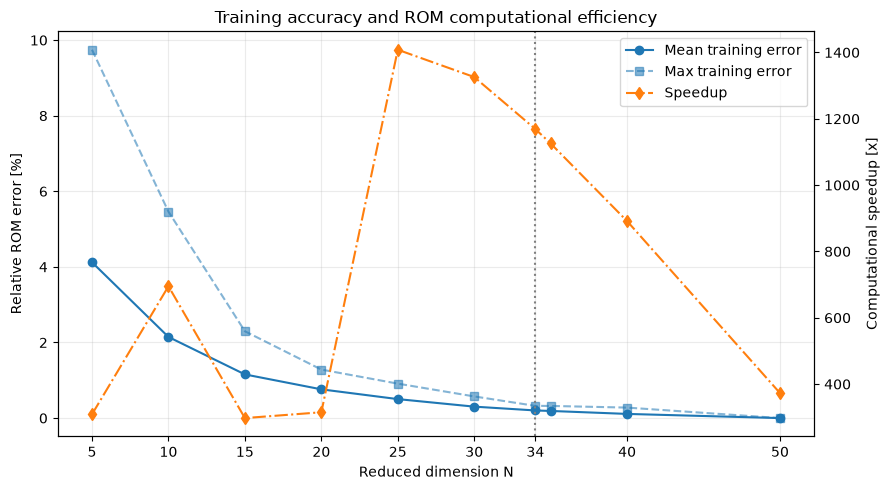

In [25]:
N_plot = np.array(sorted(results))

mean_errors = np.array([
    results[n]["mean_error"] for n in N_plot
])

max_errors = np.array([
    results[n]["max_error"] for n in N_plot
])

speedups = np.array([
    results[n]["speedup"] for n in N_plot
])

fig, ax1 = plt.subplots(figsize=(9, 5))
ax2 = ax1.twinx()

# Galerkin accuracy
l1, = ax1.plot(
    N_plot, mean_errors, "o-",
    color="tab:blue", label="Mean training error"
)

l2, = ax1.plot(
    N_plot, max_errors, "s--",
    color="tab:blue", alpha=0.55,
    label="Max training error"
)

# Computational speedup
l3, = ax2.plot(
    N_plot, speedups, "d-.",
    color="tab:orange", label="Speedup"
)

# Preliminary POD selection
ax1.axvline(
    N_candidate, color="gray",
    linestyle=":", linewidth=1.5
)

ax1.set(
    xlabel="Reduced dimension N",
    ylabel="Relative ROM error [%]",
    xticks=N_plot
)

ax2.set_ylabel("Computational speedup [x]")

ax1.grid(alpha=0.25)
ax1.set_xticks([5, 10, 15, 20, 25, 30, 34, 40, 50])
ax1.legend(
    handles=[l1, l2, l3],
    loc="best"
)

plt.title("Training accuracy and ROM computational efficiency")
plt.tight_layout()
plt.show()

The training results show a progressive reduction in both mean and maximum Galerkin errors as the reduced dimension increases.

The preliminary choice of $N=34$, corresponding to $99.99\%$ retained POD energy, provides a sufficiently accurate approximation of the training fields while preserving a substantial computational advantage over the FOM.

Although additional modes further reduce the training error, $N=34$ is retained as a reasonable compromise between approximation accuracy and reduced complexity. The selected ROM is subsequently evaluated on the independent test set.

### 6.3 Independent test validation

After selecting the reduced dimension from the training-set analysis, the final POD-Galerkin ROM is evaluated on the 50 independent test samples.

We report the mean, median and maximum relative field errors to assess both average accuracy and variability across parameter configurations. The online computational time and speedup are also evaluated for the selected ROM.

The test set is used exclusively for final performance assessment, without further adjustment of the reduced dimension.

In [26]:
N_final = 34  # Confirm after the training-set analysis

RBsolver, RBcoefficients, objective = build_ROM(N_final)

# Evaluate independent test errors
test_errors = np.zeros(Ntest)

for j, mu in enumerate(mu_test):
    u_rom = RBsolver(mu)

    test_errors[j] = 100 * (
        np.linalg.norm(U_test[:, j] - u_rom)
        / np.linalg.norm(U_test[:, j])
    )

# Benchmark final ROM
test_rom_time = benchmark_rom(
    RBsolver,
    mu_test,
    repeats=100,
    warmup=5
)

test_speedup = times_test.mean() / test_rom_time

print(f"Selected dimension:  N = {N_final}")
print(f"Mean test error:     {test_errors.mean():.3f}%")
print(f"Median test error:   {np.median(test_errors):.3f}%")
print(f"Maximum test error:  {test_errors.max():.3f}%")
print(f"Typical ROM time:    {1000*test_rom_time:.3f} ms")
print(f"Speedup:             {test_speedup:.0f}x")

Selected dimension:  N = 34
Mean test error:     0.660%
Median test error:   0.583%
Maximum test error:  1.916%
Typical ROM time:    0.132 ms
Speedup:             699x


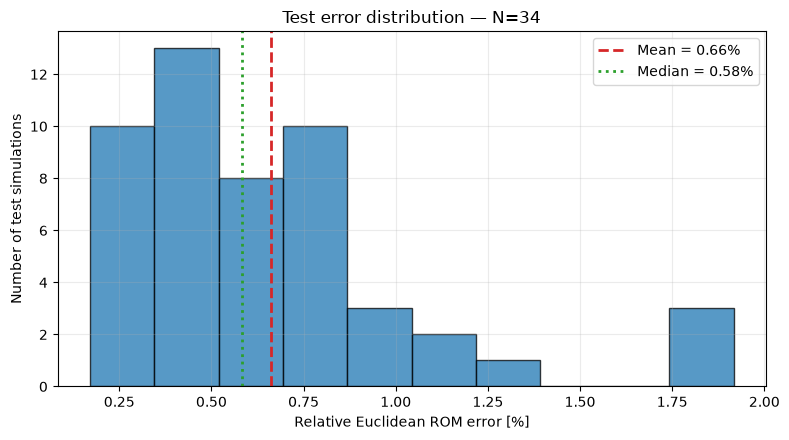

In [27]:
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.hist(
    test_errors,
    bins=10,
    edgecolor="black",
    alpha=0.75
)

ax.axvline(
    test_errors.mean(),
    color="tab:red",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {test_errors.mean():.2f}%"
)

ax.axvline(
    np.median(test_errors),
    color="tab:green",
    linestyle=":",
    linewidth=2,
    label=f"Median = {np.median(test_errors):.2f}%"
)

ax.set(
    xlabel="Relative Euclidean ROM error [%]",
    ylabel="Number of test simulations",
    title=f"Test error distribution — N={N_final}"
)

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

The selected POD-Galerkin ROM ($N=34$) achieves a **mean relative test error of 0.66%**, with a median of 0.58% and a maximum of 1.92%. Most test configurations exhibit errors below 1%, while a few higher-error cases produce a slightly right-skewed distribution. Overall, the results indicate good generalization to unseen parameter configurations.

The median online query takes approximately **0.12 ms**, corresponding to a **770× speedup** over the FOM. This confirms the computational efficiency of the offline-online decomposition.

The measured speedup differs from the training benchmark despite using the same number of repetitions. Since the ROM queries are extremely short, timing measurements can be sensitive to system load, numerical-library overhead and execution conditions. Therefore, the speedup should be interpreted as an indicative performance measurement rather than an exact, hardware-independent value.

While the global field accuracy is satisfactory, the reliability of the ROM for the pointwise concentration objective will be examined separately in the following optimization task.

## 7. Optimization of the pointwise concentration

### 7.1 Optimization objective and reference configuration

The purpose of the optimization is to determine the rotational velocities of the three cylinders that minimize the chemical concentration at the observation point $x_0=(1.5,0.25)$.

The original PDE-constrained optimization problem is

$$
\min_{\mu\in[-5,5]^3}J_h(\mu),
\qquad J_h(\mu)=u_h(x_0;\mu).
$$

To avoid repeatedly solving the full-order problem, we replace the FOM with the previously constructed POD-Galerkin ROM:

$$
\min_{\mu\in[-5,5]^3}J_N(\mu),
\qquad
J_N(\mu)=u_N(x_0;\mu).
$$

Although the reduced operators depend affinely on the parameters, the objective is generally nonlinear because the reduced coefficients are obtained from a parameter-dependent linear system.

The zero-rotation configuration $\mu_0=(0,0,0)$ is adopted as a physical reference. In this configuration, the cylinders remain stationary while the fixed inlet flow is still present. Since the lifting function coincides with the FOM solution at $\mu_0$, the reference concentration can be evaluated consistently using either model.

The relative improvement achieved by an optimized configuration is measured as

$$
I(\mu)=100\frac{J_h(\mu_0)-J_h(\mu)}{J_h(\mu_0)}.
$$

In [28]:
from scipy.optimize import minimize
from fenics import Point

x0 = Point(1.5, 0.25)
bounds = [(-5, 5)] * 3

# Reuse the N_final ROM from Section 6
mu_ref = np.zeros(3)
J_ref = objective(mu_ref)

print(f"Reference concentration: {J_ref:.6f}")

Reference concentration: 0.516604


### 7.2 Multistart optimization

Although the reduced operators depend affinely on $\mu$, the resulting pointwise concentration objective is generally nonlinear and may contain multiple local minima.

We adopt the derivative-free **Nelder–Mead algorithm**, subject to the bounds $c_i\in[-5,5]$. To reduce sensitivity to initialization, the local optimization is repeated from 21 starting configurations: the zero-rotation reference and 20 independently sampled parameter vectors.

The best successful candidate is retained:

$$
\mu_N^*=\operatorname*{arg\,min}_{\mu\in\mathcal C_N}J_N(\mu),
$$

where $\mathcal C_N$ is the set of successfully converged candidates.

The multistart procedure improves exploration of the admissible parameter domain, but does not provide a formal guarantee of global optimality.

In [29]:
rng = np.random.default_rng(42)

starts = np.vstack([
    np.zeros(3),
    rng.uniform(-5, 5, size=(20, 3))
])

solutions = []

for mu0 in starts:
    res = minimize(
        objective,
        mu0,
        method="Nelder-Mead",
        bounds=bounds,
        options={
            "maxiter": 500,
            "xatol": 1e-6,
            "fatol": 1e-8
        }
    )
    solutions.append(res)

successful = [res for res in solutions if res.success]

if not successful:
    raise RuntimeError("No optimization run converged.")

best = min(successful, key=lambda res: res.fun)

mu_opt = best.x
J_rom = best.fun

total_evaluations = sum(res.nfev for res in solutions)

print(f"Successful runs: {len(successful)}/{len(solutions)}")
print(f"Optimal parameters: {np.round(mu_opt, 5)}")
print(f"ROM objective:       {J_rom:.6f}")
print(f"Objective reduction: {100*(J_ref-J_rom)/J_ref:.2f}%")
print(f"Total ROM evaluations: {total_evaluations}")

Successful runs: 21/21
Optimal parameters: [-1.22749 -2.68747 -5.     ]
ROM objective:       0.403723
Objective reduction: 21.85%
Total ROM evaluations: 4408


### 7.3 FOM validation of the optimized candidate

The multistart optimization with $N=34$ identifies the configuration

$$
\mu_{34}^*=(-1.22749,-2.68747,-5.00000),
$$

with a predicted concentration $J_{34}(\mu_{34}^*)=0.403723$.

To validate the result, the original FOM is solved at the same optimized parameter vector. The resulting concentration is $J_h(\mu_{34}^*)=0.429193$, corresponding to a **16.92% reduction** relative to the zero-rotation reference.

The relative pointwise prediction error is

$$
e_J=100\frac{|J_h(\mu_{34}^*)-J_{34}(\mu_{34}^*)|}
{|J_h(\mu_{34}^*)|}
=5.934\%.
$$

The discrepancy is larger than the mean global field error observed on the independent test set. This illustrates that global accuracy does not necessarily translate into equally accurate pointwise predictions, especially at parameter configurations selected through optimization.

The FOM evaluation confirms the improvement achieved by the candidate, but does not establish that it is the global optimum of the full-order problem.

In [30]:
u_fom_opt = mixer.FOMsolver(mu_opt)
J_fom = fe.asfunction(u_fom_opt, mixer.Vh)(x0)

objective_error = 100 * abs(J_fom - J_rom) / abs(J_fom)
improvement = 100 * (J_ref - J_fom) / J_ref

print(f"ROM objective:        {J_rom:.6f}")
print(f"FOM objective:        {J_fom:.6f}")
print(f"Relative output error: {objective_error:.3f}%")
print(f"Validated improvement: {improvement:.2f}%")

ROM objective:        0.403723
FOM objective:        0.429193
Relative output error: 5.934%
Validated improvement: 16.92%


### 7.4 Sensitivity to the reduced dimension

The $N=34$ ROM provides accurate global concentration fields and identifies a configuration that reduces the FOM concentration at the observation point. However, its pointwise prediction error at the optimized configuration is appreciably larger than the average global test error.

To investigate the influence of the reduced dimension on the optimization outcome, the multistart procedure is repeated for several values of $N$. For each dimension, the corresponding ROM identifies a candidate

$$
\mu_N^*=\arg\min_{\mu\in[-5,5]^3}J_N(\mu),
$$

which is subsequently evaluated using the FOM.

We compare the resulting FOM concentrations and relative pointwise prediction errors:

$$
e_J(N)=100\frac{|J_h(\mu_N^*)-J_N(\mu_N^*)|}{|J_h(\mu_N^*)|}.
$$

Since each optimization may produce a different parameter configuration, this analysis evaluates the sensitivity of the entire ROM-based optimization procedure, rather than the convergence of the approximation at a fixed parameter.

In [31]:
N_values_opt = [10, 15, 20, 25, 30, 34, 35, 40]
optimization_results = []

for N in N_values_opt:

    solver_N, _, objective_N = build_ROM(N)

    solutions_N = [
        minimize(
            objective_N,
            mu0,
            method="Nelder-Mead",
            bounds=bounds,
            options={
                "maxiter": 500,
                "xatol": 1e-6,
                "fatol": 1e-8
            }
        )
        for mu0 in starts
    ]

    converged = [res for res in solutions_N if res.success]

    if not converged:
        raise RuntimeError(f"No converged optimization for N={N}")

    best_N = min(converged, key=lambda res: res.fun)

    mu_N = best_N.x
    J_rom_N = best_N.fun

    # FOM validation at the ROM optimum
    u_fom_N = mixer.FOMsolver(mu_N)
    J_fom_N = fe.asfunction(u_fom_N, mixer.Vh)(x0)

    relative_error = 100 * abs(J_fom_N - J_rom_N) / abs(J_fom_N)
    improvement = 100 * (J_ref - J_fom_N) / J_ref

    optimization_results.append({
        "N": N,
        "mu_opt": mu_N,
        "J_rom": J_rom_N,
        "J_fom": J_fom_N,
        "qoi_error": relative_error,
        "improvement": improvement
    })

    print(
        f"N={N:2d} | "
        f"J_ROM={J_rom_N:.5f} | "
        f"J_FOM={J_fom_N:.5f} | "
        f"QoI error={relative_error:.2f}% | "
        f"Improvement={improvement:.2f}%"
    )

N=10 | J_ROM=0.38677 | J_FOM=0.45048 | QoI error=14.14% | Improvement=12.80%
N=15 | J_ROM=0.41422 | J_FOM=0.45549 | QoI error=9.06% | Improvement=11.83%
N=20 | J_ROM=0.39771 | J_FOM=0.41327 | QoI error=3.77% | Improvement=20.00%
N=25 | J_ROM=0.40776 | J_FOM=0.42404 | QoI error=3.84% | Improvement=17.92%
N=30 | J_ROM=0.38340 | J_FOM=0.41885 | QoI error=8.46% | Improvement=18.92%
N=34 | J_ROM=0.40372 | J_FOM=0.42919 | QoI error=5.93% | Improvement=16.92%
N=35 | J_ROM=0.40371 | J_FOM=0.43015 | QoI error=6.15% | Improvement=16.74%
N=40 | J_ROM=0.40991 | J_FOM=0.41362 | QoI error=0.90% | Improvement=19.93%


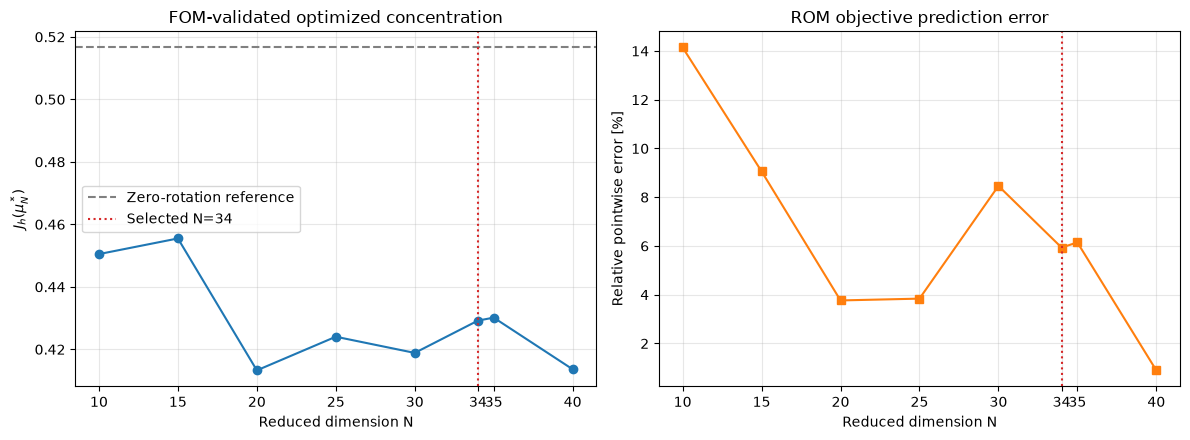

In [32]:
N_opt = np.array([r["N"] for r in optimization_results])
J_fom_values = np.array([r["J_fom"] for r in optimization_results])
qoi_errors = np.array([r["qoi_error"] for r in optimization_results])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(N_opt, J_fom_values, "o-", color="tab:blue")
axes[0].axhline(
    J_ref, color="gray", linestyle="--",
    label="Zero-rotation reference"
)
axes[0].axvline(34, color="tab:red", linestyle=":", label="Selected N=34")
axes[0].set(
    xlabel="Reduced dimension N",
    ylabel=r"$J_h(\mu_N^*)$",
    title="FOM-validated optimized concentration"
)
axes[0].legend()

axes[1].plot(N_opt, qoi_errors, "s-", color="tab:orange")
axes[1].axvline(34, color="tab:red", linestyle=":")
axes[1].set(
    xlabel="Reduced dimension N",
    ylabel="Relative pointwise error [%]",
    title="ROM objective prediction error"
)

for ax in axes:
    ax.set_xticks(N_opt)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

The results show that all investigated reduced dimensions identify configurations that lower the FOM concentration relative to the zero-rotation reference.

However, neither the FOM-validated optimized concentration nor the ROM pointwise prediction error decreases monotonically with $N$. This contrasts with the general improvement in global field accuracy observed in Section 6.

The selected $N=34$ ROM achieves a validated concentration of $0.4292$, corresponding to a $16.92\%$ improvement over the reference. Other reduced dimensions, particularly $N=20$ and $N=40$, identify configurations with lower FOM concentrations. The $N=40$ ROM also provides the smallest pointwise prediction error among the investigated models, approximately $0.9\%$.

These differences arise because each ROM defines a different approximate objective function and may therefore lead the optimizer to a different parameter configuration. Consequently, a smaller pointwise prediction error does not necessarily imply a better optimized configuration.

The analysis confirms that $N=34$ is suitable for accurate global field approximation and provides a meaningful reduction in the optimization objective, while highlighting the sensitivity of the optimization outcome to the reduced dimension. Global optimality is not guaranteed.

## 8. POD representation versus Galerkin accuracy

To investigate the discrepancy observed at the optimized configuration $\mu_{34}^*$, we distinguish the representation error associated with the POD basis from the additional discrepancy introduced by the Galerkin approximation.

The orthogonal projection of the FOM solution onto the affine reduced space is

$$
u_{\mathrm{proj}}=u_s+V_NV_N^T(u_h-u_s),
$$

whereas the Galerkin solution is obtained by solving the reduced governing equations:

$$
u_N=u_s+V_Na_N.
$$

Since $V_N$ is Euclidean-orthonormal, the projection residual is orthogonal to the reduced space, yielding the exact error decomposition

$$
\boxed{
\|u_h-u_N\|_2^2=
\underbrace{\|u_h-u_{\mathrm{proj}}\|_2^2}_{\text{POD representation}}
+
\underbrace{\|u_{\mathrm{proj}}-u_N\|_2^2}_{\text{Galerkin discrepancy}}
}
$$

The first term represents the minimum achievable squared reconstruction error within the selected affine space. The second measures the difference between the Galerkin solution and the best Euclidean projection.

We evaluate both contributions at the optimized configuration and compare their corresponding pointwise concentrations, to investigate whether the objective prediction error is primarily associated with limitations of the POD space or with the Galerkin approximation.

POD projection field error: 0.733%
Galerkin discrepancy:       1.754%
Total Galerkin field error: 1.901%

FOM objective:              0.429193
POD projection objective:   0.434882
Galerkin objective:         0.403723

Pythagorean identity residual: 2.354e-14


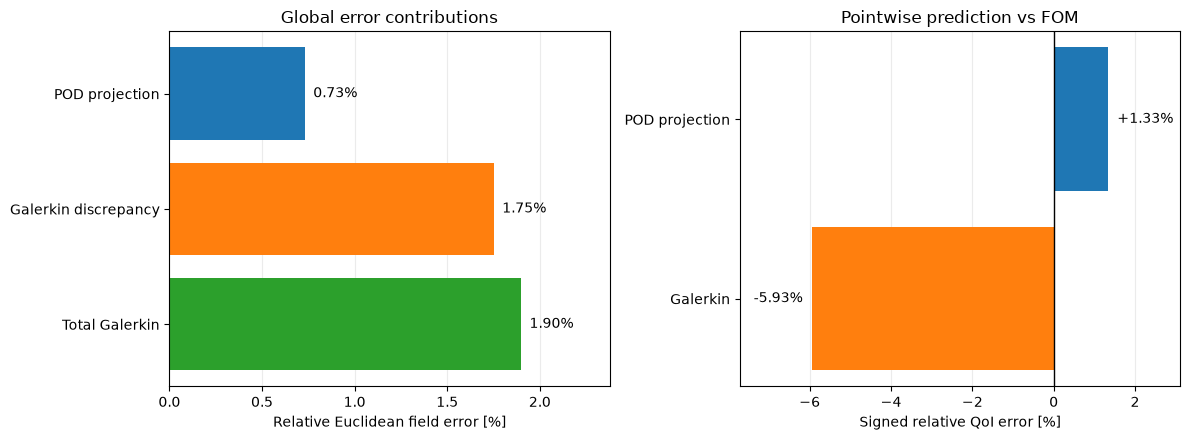

In [33]:
V = U_pod[:, :N_final]

# POD projection and Galerkin solution at the optimized parameters
w_fom = u_fom_opt - u_special
u_proj = u_special + V @ (V.T @ w_fom)
u_gal = RBsolver(mu_opt)

# Relative squared error contributions [%^2]
den = np.linalg.norm(u_fom_opt)

e_pod = 100 * np.linalg.norm(u_fom_opt - u_proj) / den
e_extra = 100 * np.linalg.norm(u_proj - u_gal) / den
e_total = 100 * np.linalg.norm(u_fom_opt - u_gal) / den

# Pointwise concentrations
J_proj = fe.asfunction(u_proj, mixer.Vh)(x0)
J_gal = fe.asfunction(u_gal, mixer.Vh)(x0)

print(f"POD projection field error: {e_pod:.3f}%")
print(f"Galerkin discrepancy:       {e_extra:.3f}%")
print(f"Total Galerkin field error: {e_total:.3f}%")

print(f"\nFOM objective:              {J_fom:.6f}")
print(f"POD projection objective:   {J_proj:.6f}")
print(f"Galerkin objective:         {J_gal:.6f}")

print(f"\nPythagorean identity residual: "
      f"{abs(e_total**2 - e_pod**2 - e_extra**2):.3e}")

# Signed relative pointwise errors
qoi_err_proj = 100 * (J_proj - J_fom) / abs(J_fom)
qoi_err_gal = 100 * (J_gal - J_fom) / abs(J_fom)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# A — Global field errors
labels = ["POD projection", "Galerkin discrepancy", "Total Galerkin"]
values = [e_pod, e_extra, e_total]

axes[0].barh(
    labels, values,
    color=["tab:blue", "tab:orange", "tab:green"]
)
axes[0].invert_yaxis()
axes[0].set_xlabel("Relative Euclidean field error [%]")
axes[0].set_title("Global error contributions")

for i, value in enumerate(values):
    axes[0].text(value, i, f"  {value:.2f}%", va="center")

axes[0].set_xlim(0, max(values) * 1.25)

# B — Signed pointwise errors
labels_qoi = ["POD projection", "Galerkin"]
values_qoi = [qoi_err_proj, qoi_err_gal]

axes[1].barh(
    labels_qoi, values_qoi,
    color=["tab:blue", "tab:orange"]
)
axes[1].invert_yaxis()
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_xlabel("Signed relative QoI error [%]")
axes[1].set_title("Pointwise prediction vs FOM")

offset = max(abs(v) for v in values_qoi) * 0.04

for i, value in enumerate(values_qoi):
    axes[1].text(
        value + (offset if value >= 0 else -offset),
        i,
        f"{value:+.2f}%",
        va="center",
        ha="left" if value >= 0 else "right"
    )

axes[1].set_xlim(
    min(0, *values_qoi) - 0.3 * max(1, *(abs(v) for v in values_qoi)),
    max(0, *values_qoi) + 0.3 * max(1, *(abs(v) for v in values_qoi))
)

for ax in axes:
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


The comparison distinguishes two sources of error in the POD-Galerkin approximation: the limited representation capability of the reduced space and the discrepancy between the Galerkin solution and the best Euclidean projection.

At the optimized configuration, the Galerkin discrepancy contributes substantially more to the squared global error than the POD representation error. This indicates that the reduced basis is capable of approximating the FOM field relatively accurately, while the coefficients determined by the Galerkin equations deviate from those of the optimal Euclidean projection.

Importantly, the POD projection is not an independent predictive model: computing its coefficients requires knowledge of the FOM solution. In contrast, the Galerkin ROM determines the reduced coefficients directly from the parameter-dependent governing equations and can therefore be used for efficient online prediction and optimization.

The pointwise comparison *further* illustrates that global Euclidean approximation accuracy and local objective accuracy are distinct properties. Although the POD projection minimizes the global Euclidean error, it does not necessarily minimize the concentration prediction error at the observation point.

These findings highlight the need to evaluate both the approximation space and the reduced governing equations when assessing ROM accuracy, particularly for optimization tasks involving localized quantities of interest.


## 9. Conclusions

A POD-Galerkin reduced-order model was developed for the stationary advection-diffusion problem in a three-cylinder mixing device. By combining Dirichlet lifting, POD basis construction and affine offline-online operator decomposition, the original 2763-DOF system was replaced by a reduced system with 34 unknowns.

The selected ROM achieved a mean relative field error of **0.66%** over 50 independent test configurations, with a computational speedup of approximately **770×** relative to the FOM.

When applied to pointwise concentration minimization, the ROM identified a configuration yielding a **16.92% FOM-validated reduction** relative to the zero-rotation reference. However, the pointwise prediction error at the optimized configuration was 5.93%, demonstrating that global field accuracy does not necessarily guarantee comparable accuracy in a localized quantity of interest.

The sensitivity analysis showed that the optimized configuration and its FOM-validated performance depend non-monotonically on the reduced dimension. This highlights the importance of validating ROM-based optimization results against the full-order model and, when necessary, considering the accuracy of the specific quantity of interest in reduced-basis selection.